# 04 · A LEO satellite pass

As a satellite crosses the sky the slant path through the atmosphere changes: at 20° elevation the light
crosses about three times more turbulence than at zenith, so r₀ shrinks several-fold. `opal pass` follows this
with **exact per-layer r₀ switching** (README §5.2):

1. the pass geometry (elevation and slant range over time) is computed for a circular orbit;
2. every layer's r₀ is scaled along the slant path, and the pass is cut into segments of constant r₀;
3. at each segment boundary the extrusion operators of every layer are rebuilt for the new r₀ while the current
   screens are kept, so the field evolves continuously while its statistics follow the pass;
4. the pass is mapped onto the run's ticks, so a several-minute pass becomes a short, statistically faithful
   sequence; captured wavefronts have their r₀ measured and compared with the target.

This is a reduced version of `configs/leo_pass_b2.json` (700 km orbit, 20°–90°–20°): 256² instead of 512²,
1000 ticks in 10 segments, 40 captures.

> **About the outputs.** The results stored in this notebook were produced on an NVIDIA GeForce RTX 4080
> (16 GiB) under Windows. Timings, and the run mode the memory guard picks, depend on the GPU; the statistics
> do not. Open the notebook in Jupyter or VS Code with the OPAL environment as the kernel and run the cells in
> order. The first cell moves to the repository root, so every path below is relative to it.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")      # hide TensorFlow's C++ start-up messages
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs").is_dir())
os.chdir(ROOT)                                           # paths below are relative to the repository root

import time
import numpy as np
import matplotlib.pyplot as plt
import opal

%matplotlib inline
plt.rcParams.update({"figure.dpi": 80, "image.origin": "lower"})
print("OPAL", opal.__version__)

OPAL 1.1.0


In [2]:
config = opal.load_config("configs/leo_pass_b2.json", overrides={"N": 256, "steps": 1000})
config["pass_params"].update(num_segments=10, wavefront_captures=40)      # 100 ticks per segment
print(config["pass_params"])

{'altitude_m': 700000.0, 'min_elevation_deg': 20.0, 'num_segments': 10, 'pass_num_samples': 1024, 'pass_window_s': None, 'wavefront_captures': 40, 'capture_to_host': True, 'regenerate_on_switch': False, 'match_initial_r0': True, 'validation_guard_frac': 0.0}


## 1. Plan the pass

`plan_pass` computes everything that does not need the GPU: the geometry, the per-layer r₀ along the pass, the
segment table and the capture ticks. The staircase below is what the simulator will apply.

pass: 400 s, elevation 20-90 deg, path r0 0.131-0.250 m
1000 ticks = 10 segments x 100 ticks, 40 captures


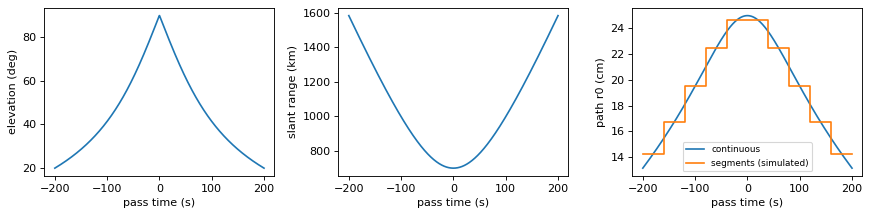

In [3]:
from opal.analysis import effective_path_r0

plan = opal.plan_pass(config)
orbit = plan.orbit_pass
print(f"pass: {orbit.duration_s:.0f} s, elevation {orbit.elevation_deg.min():.0f}-{orbit.elevation_deg.max():.0f} deg, "
      f"path r0 {np.nanmin(plan.effective_r0_t):.3f}-{np.nanmax(plan.effective_r0_t):.3f} m")
print(f"{plan.num_steps} ticks = {len(plan.segment_starts)} segments x {plan.segment_steps} ticks, "
      f"{len(plan.wavefront_steps)} captures")

seg_t = orbit.t[plan.pass_index(plan.segment_starts)]
seg_r0 = effective_path_r0(plan.schedule)
fig, axes = plt.subplots(1, 3, figsize=(11, 2.8))
axes[0].plot(orbit.t, orbit.elevation_deg)
axes[0].set(xlabel="pass time (s)", ylabel="elevation (deg)")
axes[1].plot(orbit.t, orbit.range_m / 1e3)
axes[1].set(xlabel="pass time (s)", ylabel="slant range (km)")
axes[2].plot(orbit.t, plan.effective_r0_t * 100, label="continuous")
axes[2].step(np.append(seg_t, orbit.t[-1]), np.append(seg_r0, seg_r0[-1]) * 100, where="post",
             label="segments (simulated)")
axes[2].set(xlabel="pass time (s)", ylabel="path r0 (cm)")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 2. Run it

Each segment line reports the target path r₀ and the median r₀ measured on that segment's captures.

In [4]:
out = opal.run_pass(config, "runs/leo_pass")

[opal    0.04s] pass: 700 km orbit, elevation 20.0-89.9 deg over 400 s
[opal    0.04s] schedule: 10 segments x 100 steps = 1000, path r0 0.131-0.250 m, 40 wavefront captures
[opal    0.04s] building simulator: N=256, 10 layers


[opal   12.91s] built simulator in 12.9 s
[opal   12.91s] seed 20260716


[opal   51.47s] segment   1/10 elev  23.1 deg target r0 0.143 m measured 0.150 m (4 captures, 38.54 s)


[opal   82.13s] segment   2/10 elev  30.8 deg target r0 0.167 m measured 0.163 m (4 captures, 30.67 s)


[opal  107.07s] segment   3/10 elev  41.5 deg target r0 0.195 m measured 0.180 m (4 captures, 24.94 s)


...

[opal  195.92s] segment   6/10 elev  77.8 deg target r0 0.247 m measured 0.287 m (4 captures, 33.46 s)


[opal  220.13s] segment   7/10 elev  56.6 deg target r0 0.225 m measured 0.255 m (4 captures, 24.21 s)


[opal  250.27s] segment   8/10 elev  41.3 deg target r0 0.195 m measured 0.247 m (4 captures, 30.14 s)


[opal  274.33s] segment   9/10 elev  30.7 deg target r0 0.167 m measured 0.175 m (4 captures, 24.06 s)


[opal  302.73s] segment  10/10 elev  23.0 deg target r0 0.143 m measured 0.168 m (4 captures, 28.40 s)
[opal  302.75s] done: 1000 steps in 289.8 s | peak GPU 0.04 GiB | measured/theory r0 median 1.083
[opal  302.76s] wrote runs\leo_pass


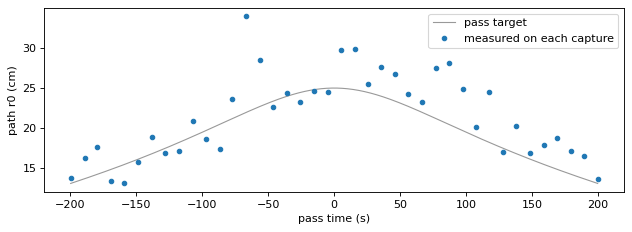

measured / target r0: median 1.083 over 40 captures
wavefronts: (40, 256, 256) -> runs/leo_pass/wavefronts.npy


In [5]:
rec = out["records"]
t = np.array([r["pass_time_s"] for r in rec])
measured = np.array([r["measured_r0"] for r in rec])
target = np.array([r["theoretical_r0"] for r in rec])

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(orbit.t, plan.effective_r0_t * 100, color="0.6", lw=1, label="pass target")
ax.plot(t, measured * 100, "o", ms=4, label="measured on each capture")
ax.set(xlabel="pass time (s)", ylabel="path r0 (cm)")
ax.legend()
plt.tight_layout()
plt.show()

ok = np.isfinite(measured)
print(f"measured / target r0: median {np.median(measured[ok] / target[ok]):.3f} over {ok.sum()} captures")
print("wavefronts:", out["wavefronts"].shape, "->", "runs/leo_pass/wavefronts.npy")

Two effects keep the points off the curve:

- **Refresh lag.** The screens are kept at each switch, so a layer only reaches its new r₀ once its screen has
  scrolled through (about `N / rows_extruded` ticks; the slow ground layer takes over a hundred at 256²). The
  measured r₀ therefore trails the target: it tends to sit below it while r₀ grows towards zenith and above it
  on the way down. Longer segments, or `regenerate_on_switch`, reduce this.
- **Small grid.** At 256² the grid is only about ten r₀ across, and the estimator reads r₀ a little high on small
  grids (README §5.2). The full 512², 30-segment B2 case gives a median ratio of 0.99.

## 3. The pass as the ground station sees it

The 40 captured wavefronts in order (centre 1.9 m). Near the horizon (start and end) r₀ is small: the phase is
finely structured and the irradiance breaks into speckle. Near zenith the field is much calmer.

In [6]:
from PIL import Image, ImageDraw
from opal.viewer import field_images

MEDIA = Path("examples/media")          # GIFs live next to the notebooks so the markdown can show them
MEDIA.mkdir(exist_ok=True)


def save_gif(frames, path, *, fps=12, size=128, crop=None, labels=None, colors=32):
    """Irradiance (left) and wrapped phase (right) of every field, one GIF frame each."""
    hot, cyclic = plt.get_cmap("inferno"), plt.get_cmap("twilight")
    images = []
    for k, frame in enumerate(frames):
        frame = np.asarray(frame)
        if crop:
            c, h = frame.shape[-1] // 2, crop // 2
            frame = frame[c - h:c + h, c - h:c + h]
        irr, phase = field_images(frame)
        rgb = np.concatenate([hot(np.clip(irr / 3, 0, 1)), cyclic((phase + np.pi) / (2 * np.pi))], axis=1)
        img = Image.fromarray((rgb[::-1, :, :3] * 255).astype(np.uint8)).resize((2 * size, size), Image.BILINEAR)
        if labels is not None:
            ImageDraw.Draw(img).text((4, 2), labels[k], fill=(255, 255, 255))
        images.append(img.quantize(colors=colors))
    images[0].save(path, save_all=True, append_images=images[1:], duration=int(1000 / fps), loop=0)
    print(f"wrote {Path(path).as_posix()}: {len(images)} frames, {Path(path).stat().st_size / 1024:.0f} KiB")


labels = [f"t {r['pass_time_s']:+5.0f} s  elev {r['elevation_deg']:4.1f} deg  r0 {r['theoretical_r0'] * 100:4.1f} cm"
          for r in rec]
save_gif(out["wavefronts"], MEDIA / "04_leo_pass.gif", fps=5, size=150, crop=192, labels=labels)

wrote examples/media/04_leo_pass.gif: 40 frames, 740 KiB


![LEO pass: irradiance (left) and phase (right) of the captured wavefronts](media/04_leo_pass.gif)

## CLI equivalent

```bash
opal pass -c configs/leo_pass_b2.json --grid 256 --steps 1000 --segments 10 --captures 40 -o runs/leo_pass
opal view runs/leo_pass                     # captures with the measured vs target r0 strip
opal pass -c configs/leo_pass_b2.json       # the full 512^2, 30-segment case
```